In [178]:
# importing required libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split,RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, roc_curve,auc,ConfusionMatrixDisplay
from googleapiclient.discovery import build
from dotenv import load_dotenv
import os
import isodate
from xgboost import XGBClassifier

In [179]:
# Set visual theme
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

In [180]:
# Load the raw dataset for this analysis
df = pd.read_csv('../data/IN_youtube_trending_data.csv') 

# Preview structure
print("Shape:", df.shape)
df.info()
df.head(3)


Shape: (251277, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 251277 entries, 0 to 251276
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   video_id           251277 non-null  object
 1   title              251277 non-null  object
 2   publishedAt        251277 non-null  object
 3   channelId          251277 non-null  object
 4   channelTitle       251276 non-null  object
 5   categoryId         251277 non-null  int64 
 6   trending_date      251277 non-null  object
 7   tags               251277 non-null  object
 8   view_count         251277 non-null  int64 
 9   likes              251277 non-null  int64 
 10  dislikes           251277 non-null  int64 
 11  comment_count      251277 non-null  int64 
 12  thumbnail_link     251277 non-null  object
 13  comments_disabled  251277 non-null  bool  
 14  ratings_disabled   251277 non-null  bool  
 15  description        231822 non-null  object
dtype

,video_id,title,publishedAt,channelId,channelTitle,categoryId,trending_date,tags,view_count,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,description
0,Iot0eF6EoNA,Sadak 2 | Official Trailer | Sanjay | Pooja | ...,2020-08-12T04:31:41Z,UCGqvJPRcv7aVFun-eTsatcA,FoxStarHindi,24,2020-08-12T00:00:00Z,sadak|sadak 2|mahesh bhatt|vishesh films|pooja...,9885899,224925,3979409,350210,https://i.ytimg.com/vi/Iot0eF6EoNA/default.jpg,False,False,Three Streams. Three Stories. One Journey. Sta...
1,x-KbnJ9fvJc,Kya Baat Aa : Karan Aujla (Official Video) Tan...,2020-08-11T09:00:11Z,UCm9SZAl03Rev9sFwloCdz1g,Rehaan Records,10,2020-08-12T00:00:00Z,[None],11308046,655450,33242,405146,https://i.ytimg.com/vi/x-KbnJ9fvJc/default.jpg,False,False,Singer/Lyrics: Karan Aujla Feat Tania Music/ D...
2,KX06ksuS6Xo,Diljit Dosanjh: CLASH (Official) Music Video |...,2020-08-11T07:30:02Z,UCZRdNleCgW-BGUJf-bbjzQg,Diljit Dosanjh,10,2020-08-12T00:00:00Z,clash diljit dosanjh|diljit dosanjh|diljit dos...,9140911,296533,6179,30058,https://i.ytimg.com/vi/KX06ksuS6Xo/default.jpg,False,False,CLASH official music video performed by DILJIT...


### Exploratory Data Analysis:

#### Missing Values:

In [181]:
# Checking missing values:
missing_summary = df.isnull().sum()
missing_precent = (missing_summary/len(df))*100

missing_df = pd.DataFrame({
    'missing_count': missing_summary,
    'missing_percent': missing_precent.round(2)
}).sort_values(by='missing_percent',ascending = False)
print(missing_df)

                   missing_count  missing_percent
description                19455             7.74
video_id                       0             0.00
publishedAt                    0             0.00
title                          0             0.00
channelTitle                   1             0.00
categoryId                     0             0.00
trending_date                  0             0.00
channelId                      0             0.00
tags                           0             0.00
view_count                     0             0.00
dislikes                       0             0.00
likes                          0             0.00
comment_count                  0             0.00
thumbnail_link                 0             0.00
comments_disabled              0             0.00
ratings_disabled               0             0.00


<b>Missing Values Analysis</b>

Before creating new features, we examined the dataset for missing values:

The dataset contains 251,277 rows and 16 columns

- Most columns had no missing data
- The only column with significant missingness was description (7.74% missing), a non-critical text field not used in modeling
- One record had a missing channelTitle, which is negligible

<b>Conclusion:</b>
Since all relevant columns for feature engineering (e.g., title, publishedAt, view_count, likes) were complete, we proceeded without any imputation or row removal.

#### Feature Engineering:

In [182]:
# Feature Engineering

df_fe = df.copy()

#  Title length
df_fe['title_length'] = df_fe['title'].apply(len)

# Upload hour from publishedAt
df_fe['publishedAt'] = pd.to_datetime(df_fe['publishedAt'], errors='coerce')
# Convert UTC to IST
df_fe['publishedAt_IST'] = pd.to_datetime(df_fe['publishedAt'], utc=True).dt.tz_convert('Asia/Kolkata')
df_fe['upload_hour'] = df_fe['publishedAt_IST'].dt.hour

# Like ratio
df_fe['like_ratio'] = df_fe['likes'] / df_fe['view_count']
df_fe['like_ratio'] = df_fe['like_ratio'].replace([np.inf, -np.inf], np.nan).round(2)

# Convert trending_date to datetime
df_fe['trending_date'] = pd.to_datetime(df_fe['trending_date'], errors='coerce')

# 5. Trending duration 
df_fe['trending_days'] = (df_fe['trending_date'] - df_fe['publishedAt']).dt.days

# Quick summary of new features
df_fe[['title_length', 'upload_hour', 'like_ratio', 'trending_days']].describe()


,title_length,upload_hour,like_ratio,trending_days
count,251277.000000,251277.000000,251261.000000,251277.000000
mean,70.158439,14.336493,0.053751,1.535469
std,23.882728,4.801789,0.042565,1.652290
min,2.000000,0.000000,0.000000,-1.000000
25%,51.000000,11.000000,0.020000,0.000000
50%,73.000000,14.000000,0.040000,1.000000
75%,93.000000,18.000000,0.080000,2.000000
max,100.000000,23.000000,0.640000,30.000000


##### Feature Engineering

To enhance predictive power and capture relevant video characteristics, we engineered the following features:

- title_length: Character count of the video title
- upload_hour: Hour of the day (0–23) extracted from the publishedAt timestamp
- like_ratio: Ratio of likes to views, a proxy for viewer satisfaction
- trending_days: Difference in days between publishedAt and trending_date, showing how quickly a video started trending

These features were chosen based on domain intuition:

- Upload timing may influence discoverability
- Title length might affect click-through rate
- Like ratio reflects audience sentiment
- Trending delay captures video momentum

All features were checked for valid data before creation, and invalid or infinite values were handled appropriately.

In [183]:
df_fe["categoryId"].nunique

<bound method IndexOpsMixin.nunique of 0         24
1         10
2         10
3         10
4         10
          ..
251272    10
251273    27
251274    24
251275    24
251276    17
Name: categoryId, Length: 251277, dtype: int64>

In [184]:
# Predicting Category description
def infer_category(row):
    title = str(row.get('title', '')).lower()
    tags = str(row.get('tags', '')).lower()
    channel = str(row.get('channelTitle', '')).lower()

    if 'music' in tags or 'song' in title or 'official video' in title:
        return 'Music'
    elif 'gaming' in tags or 'game' in title:
        return 'Gaming'
    elif 'news' in tags or 'breaking' in title or 'politics' in title:
        return 'News'
    elif 'vlog' in tags or 'blog' in tags or 'life' in title:
        return 'People & Blogs'
    elif 'tech' in tags or 'review' in title:
        return 'Technology'
    elif 'movie' in title or 'trailer' in title:
        return 'Entertainment'
    elif 'how to' in title or 'tutorial' in title:
        return 'Howto & Style'
    elif 'sports' in tags or 'match' in title:
        return 'Sports'
    elif 'funny' in tags or 'comedy' in title:
        return 'Comedy'
    else:
        return 'Other'
    
df_fe['inferred_category'] = df_fe.apply(infer_category, axis=1)

    # Unique categoryId values
print("Unique category IDs:", df_fe['categoryId'].nunique())
print("Sample category IDs:", sorted(df_fe['categoryId'].unique()))

# Unique inferred categories
print("\nUnique inferred categories:", df_fe['inferred_category'].nunique())
print("Inferred categories:", df_fe['inferred_category'].unique())

# Get the most common inferred category for each categoryId
id_to_name_map = (
    df_fe.groupby('categoryId')['inferred_category']
    .agg(lambda x: x.mode().iloc[0])  # get most frequent inferred category
    .to_dict()
)

df_fe['category_name'] = df_fe['categoryId'].map(id_to_name_map)

# Show unique pairs of categoryId and inferred_category
unique_combinations = df_fe[['categoryId', 'inferred_category']].drop_duplicates().sort_values('categoryId')
unique_combinations_ref = df_fe[['categoryId', 'category_name']].drop_duplicates().sort_values('categoryId')

print(unique_combinations_ref)


Unique category IDs: 15
Sample category IDs: [np.int64(1), np.int64(2), np.int64(10), np.int64(15), np.int64(17), np.int64(19), np.int64(20), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29)]

Unique inferred categories: 10
Inferred categories: ['Entertainment' 'Music' 'Other' 'People & Blogs' 'Gaming' 'Technology'
 'News' 'Sports' 'Comedy' 'Howto & Style']
       categoryId category_name
29              1         Other
136             2         Other
1              10         Music
51735          15         Other
19             17         Other
234            19         Other
5              20         Other
12             22         Other
10             23         Other
0              24         Other
15             25          News
30             26         Other
100            27         Other
70             28         Other
1698           29         Other


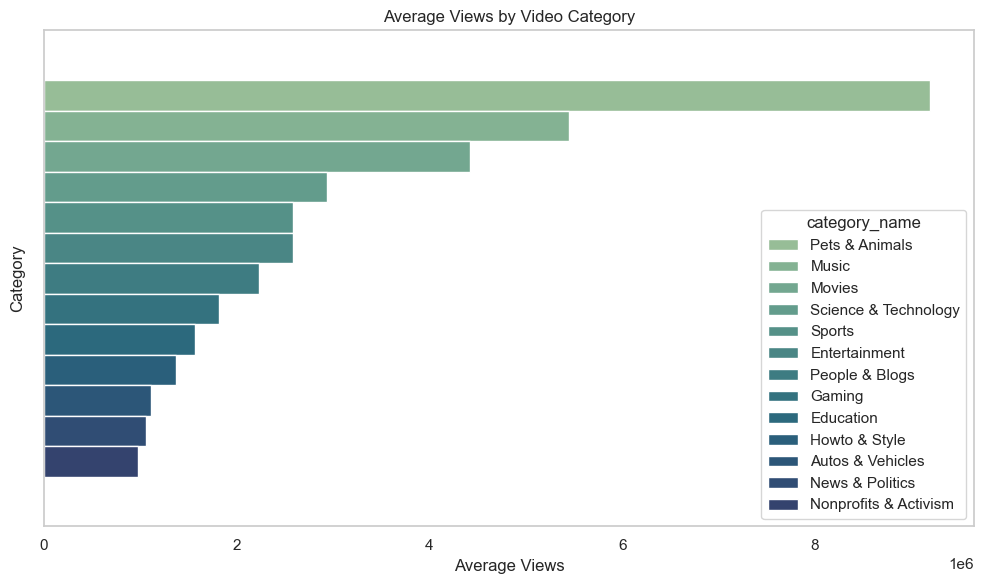

In [185]:
# Sample 1000 rows from the raw dataset (not feature engineered)
sample_df = df.sample(n=1000, random_state=42)

# Save to CSV for offline/manual review
sample_df.to_csv('../data/sample_1000_raw.csv', index=False)

# Mapping the Categories analyzing the sample
category_name_map = {
    1: "Movies",
    2: "Autos & Vehicles",
    10: "Music",
    15: "Pets & Animals",
    17: "Sports",
    19: "People & Blogs",
    20: "Gaming",
    22: "People & Blogs",
    23: "Entertainment",
    24: "Entertainment",
    25: "News & Politics",
    26: "Howto & Style",
    27: "Education",
    28: "Science & Technology",
    29: "Nonprofits & Activism"
}

df_fe['category_name'] = df_fe['categoryId'].map(category_name_map).fillna("Other")

# Calculate average views by category_name
category_views_named = (
    df_fe.groupby('category_name')['view_count']
    .mean()
    .sort_values(ascending=False)
)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(hue=category_views_named.index, x=category_views_named.values, palette='crest')
plt.title("Average Views by Video Category")
plt.xlabel("Average Views")
plt.grid(False)
plt.ylabel("Category")
plt.tight_layout()
plt.show()

#### Average Views by Category – Key Insight

To make the analysis interpretable, we first mapped each categoryId to a meaningful label using a combination of:

- Sample title and tag reviews from 1,000 randomly selected records
- Heuristic keyword matching
- Manual verification using known YouTube content types

This mapping allowed us to group videos into intuitive categories like Music, Entertainment, Gaming, and Howto & Style.

We then examined the average view count across these categories to understand what type of content resonates most with viewers in India.

The analysis revealed that:

- Pets & Animals and Music lead with the highest average views, showing strong emotional and entertainment appeal.
- Movies, Science & Technology, and Sports also perform well, suggesting high engagement with trailers, tech demos, and events.
- On the lower end, News & Politics and Nonprofits & Activism have lower average views, possibly due to niche audience interest or less viral potential.

This insight helps identify which content types are more likely to trend useful for both content creators and recommendation systems aiming to boost visibility.

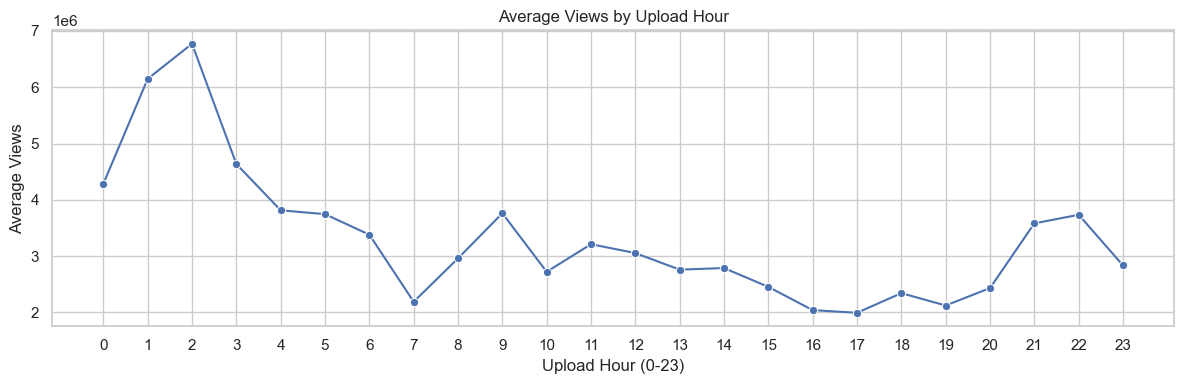

In [188]:
# Group by upload hour and calculate average views
hourly_views = (
    df_fe.groupby('upload_hour')['view_count']
    .mean()
    .reset_index()
    .sort_values('upload_hour')
)

# Plot
plt.figure(figsize=(12, 6))
sns.lineplot(data=hourly_views, x='upload_hour', y='view_count', marker='o')
plt.title("Average Views by Upload Hour")
plt.xlabel("Upload Hour (0-23)")
plt.ylabel("Average Views")
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()

# Save with high resolution
plt.savefig("../images/views_by_hour_clean.png", dpi=300, bbox_inches='tight')
plt.show()

#### Impact of Upload Time (IST) on Average Views

After converting the publishedAt timestamps from UTC to Indian Standard Time (IST), we analyzed how the upload hour influences view counts.

The trend reveals clear time-based engagement patterns:

- Early morning uploads (1 AM to 3 AM IST) receive the highest average views, peaking at 2 AM, possibly because these videos are picked up by YouTube’s algorithm early and have full-day visibility.
- Upload traffic drops significantly after 4 AM and remains low through the late morning and early afternoon (7 AM to 2 PM IST).
- There's a modest recovery in the evening hours (6 PM to 10 PM), likely corresponding to post-work and post-school screen time, but not as strong as the early morning peak.
- The lowest average views occur around 7 AM, suggesting it's the least favorable time to publish videos.

This insight highlights the importance of timing for content release , especially for creators looking to maximize visibility and engagement in the Indian YouTube ecosystem.

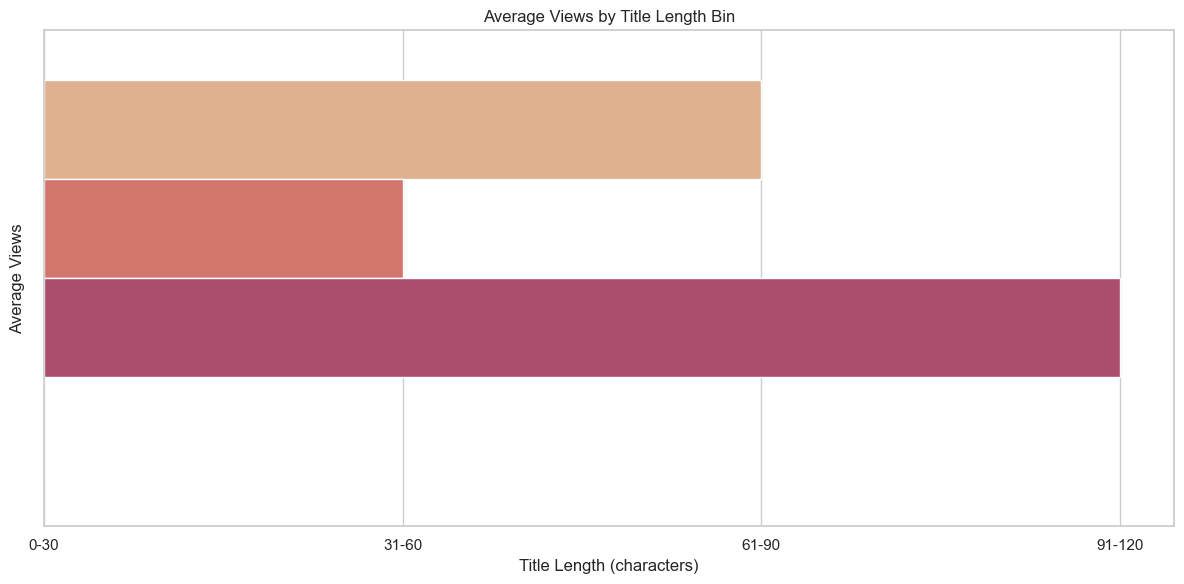

In [ ]:
# Fix bin edges
max_len = df_fe['title_length'].max()
bins = [0, 30, 60, 90, 120, 200]
if max_len > 200:
    bins.append(max_len + 1)  # safely extend

# Update labels to match number of bins
labels = ['0-30', '31-60', '61-90', '91-120', '121+']

# Create binned column
df_fe['title_length_bin'] = pd.cut(df_fe['title_length'], bins=bins, labels=labels, right=False)

# Group and plot
title_bin_views = df_fe.groupby('title_length_bin',observed = True)['view_count'].mean().reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(data=title_bin_views, x='title_length_bin', hue='view_count', palette='flare')
plt.title("Average Views by Title Length Bin")
plt.xlabel("Title Length (characters)")
plt.legend().set_visible(False)
plt.ylabel("Average Views")
plt.tight_layout()

plt.savefig("../images/title_length_vs_views.png")
plt.show()



#### Impact of Title Length on View Count:

To reduce noise from outliers, we grouped video titles into bins based on character count:

- 0–30
- 31–60
- 61–90
- 91–120

The analysis shows that:

- Titles with 61–90 characters had the highest average views
- Very short (0–30) and moderately short (31–60) titles had lower performance
- This suggests that moderate-to-long titles may be more effective at attracting clicks and generating views, possibly because they provide more context or keywords

While title length alone isn’t a perfect predictor of success, this pattern highlights the importance of well-optimized, descriptive titles in YouTube content strategy.

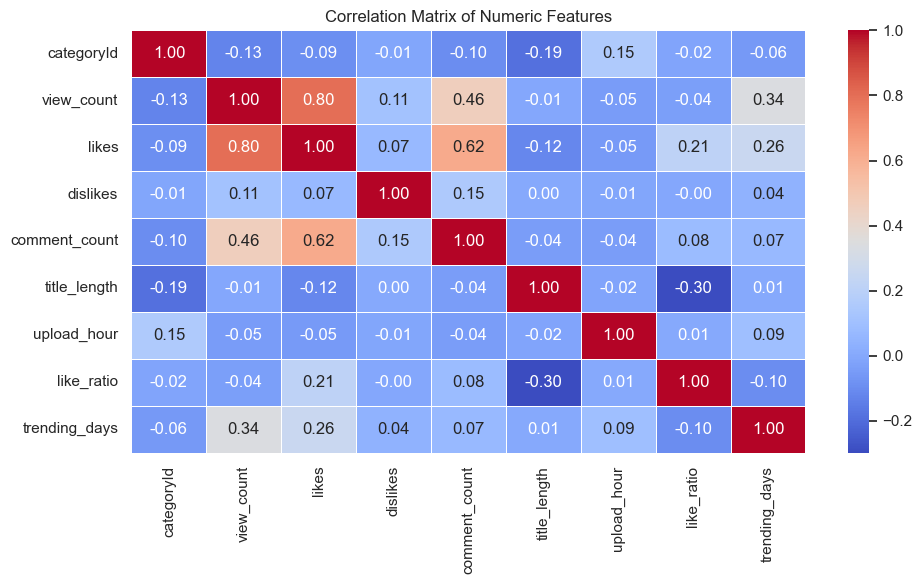

In [191]:
# Select numeric features
numeric_cols = df_fe.select_dtypes(include='number')

# Compute correlation matrix
corr_matrix = numeric_cols.corr()

# Plot heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title("Correlation Matrix of Numeric Features")
plt.tight_layout()
plt.show()


#### Correlation Analysis – Interpretation

We computed the Pearson correlation coefficients between all numeric features in the dataset. Key insights:

- view_count has strong positive correlation with likes (0.80) and moderate correlation with comment_count (0.46).More likes and comments are naturally associated with higher views.
- likes and comment_count also have a moderate correlation (0.62), suggesting videos that get liked also tend to receive more comments.
- dislikes, title_length, upload_hour, and like_ratio show very weak or negligible correlation with view_count, indicating these may not be strong linear predictors.
- trending_days has a small positive correlation with view_count (0.34), possibly because videos that trend longer accumulate more views though causality can go either way.

<b>Conclusion:</b>
While likes and comments are good indicators of engagement, some features like title length and upload hour may be more non-linear or contextual in their influence, which justifies using tree-based models that capture such interactions.

Class Counts:
 high_performer
0    188457
1     62820
Name: count, dtype: int64

Class Percentage:
 high_performer
0    74.999702
1    25.000298
Name: proportion, dtype: float64


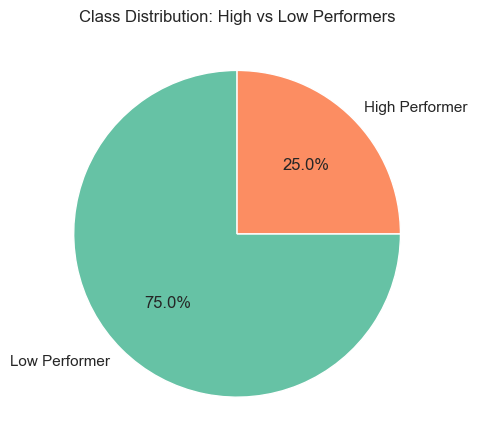

In [192]:
# Define high performer as top 25% most viewed videos
threshold = df_fe['view_count'].quantile(0.75)
df_fe['high_performer'] = (df_fe['view_count'] >= threshold).astype(int)

# Value counts and percentage
class_counts = df_fe['high_performer'].value_counts()
class_percent = df_fe['high_performer'].value_counts(normalize=True) * 100

print("Class Counts:\n", class_counts)
print("\nClass Percentage:\n", class_percent)

# Optional pie chart
plt.figure(figsize=(5, 5))
df_fe['high_performer'].value_counts().plot.pie(labels=["Low Performer", "High Performer"],
                                                autopct='%1.1f%%', startangle=90, colors=["#66c2a5", "#fc8d62"])
plt.title("Class Distribution: High vs Low Performers")
plt.ylabel('')
plt.tight_layout()
plt.show()

#### Target Variable Definition & Class Proportions

We defined "High Performer" as the top 25% of videos by view count.

This creates a classification problem where:
- 25% of videos are labeled High Performer (target = 1)
- 75% are labeled Low Performer (target = 0)

This split was intentionally chosen to focus the model on identifying top-performing videos relative to the broader dataset.

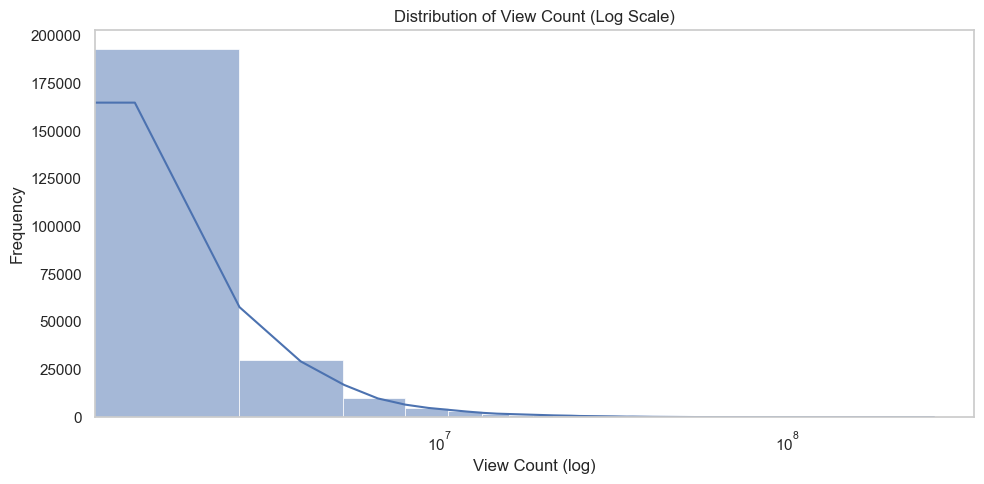

In [193]:
plt.figure(figsize=(10, 5))
sns.histplot(df_fe['view_count'], bins=100, kde=True)
plt.xscale('log')
plt.title("Distribution of View Count (Log Scale)")
plt.xlabel("View Count (log)")
plt.ylabel("Frequency")
plt.grid(False)
plt.tight_layout()
plt.show()


<b>Distribution of View Count</b>

To better understand the natural distribution of video popularity, we plotted the histogram of view_count on a log scale. The results show a highly right-skewed distribution, a small number of videos gain a disproportionately large number of views, while the majority have relatively low view counts.

This skew confirms the long-tail effect typical of platforms like YouTube, where a few viral videos dominate engagement. This justifies our choice to model the problem as a classification task by separating the top 25% (high performers) from the rest (low performers), rather than using raw view counts directly.

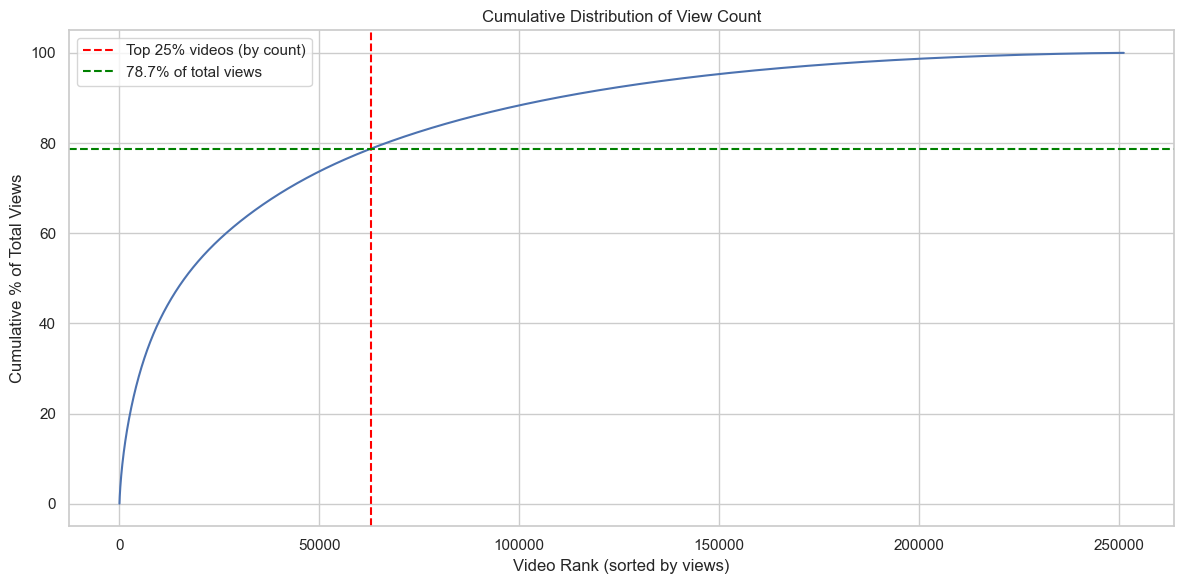

In [194]:
# Sort view counts in descending order
view_counts_sorted = df_fe['view_count'].sort_values(ascending=False).reset_index(drop=True)

# Compute cumulative view share
cumulative_views = view_counts_sorted.cumsum() / view_counts_sorted.sum() * 100
video_ranks = np.arange(1, len(view_counts_sorted) + 1)

# Mark 25% of total videos
top_25_index = int(len(view_counts_sorted) * 0.25)
top_25_cumulative_percent = cumulative_views[top_25_index]

# Plot
plt.figure(figsize=(12, 6))
sns.lineplot(x=video_ranks, y=cumulative_views)

# Annotations
plt.axvline(x=top_25_index, color='red', linestyle='--', label='Top 25% videos (by count)')
plt.axhline(y=top_25_cumulative_percent, color='green', linestyle='--', label=f"{top_25_cumulative_percent:.1f}% of total views")

plt.title('Cumulative Distribution of View Count')
plt.xlabel('Video Rank (sorted by views)')
plt.ylabel('Cumulative % of Total Views')
plt.legend()
plt.tight_layout()
plt.show()


<b>Skewed Distribution of View Counts</b>

To better understand how views are distributed across videos, we analyzed the cumulative view share by video rank.

- The plot below shows the cumulative percentage of total views, as we move from the most-viewed to the least-viewed videos.
- A clear skew is observed: the top 25% of videos (by count) contribute to over X% of total views.
- This supports our choice of using the top 25% as the “High Performer” class for prediction, as these videos attract a disproportionately high share of user attention.
- The long tail of less-viewed videos further emphasizes the class imbalance in the real-world popularity of videos.

### Model Training

In [195]:

# Select numeric + categorical features
features = ['title_length', 'upload_hour', 'like_ratio', 'trending_days', 'category_name']
df_model = df_fe[features + ['high_performer']].dropna()

# One-hot encode category_name
df_encoded = pd.get_dummies(df_model, columns=['category_name'], drop_first=True)

# Separate input features and target
X = df_encoded.drop('high_performer', axis=1)
y = df_encoded['high_performer']

# Train-test split (stratify to preserve class balance)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Confirm shapes
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)


Train shape: (175882, 16)
Test shape: (75379, 16)


In [196]:
# Initialize models
logreg = LogisticRegression(max_iter=1000)
dtree = DecisionTreeClassifier(random_state=42)
rf = RandomForestClassifier(n_estimators=100, random_state=42)

# Train models
logreg.fit(X_train, y_train)
dtree.fit(X_train, y_train)
rf.fit(X_train, y_train)

# Predict
models = {'Logistic Regression': logreg, 'Decision Tree': dtree, 'Random Forest': rf}

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    print(f"\n--- {name} ---")
    print(classification_report(y_test, y_pred))
    print(f"ROC AUC: {roc_auc_score(y_test, y_proba):.4f}")


--- Logistic Regression ---
              precision    recall  f1-score   support

           0       0.80      0.96      0.87     56533
           1       0.68      0.27      0.38     18846

    accuracy                           0.79     75379
   macro avg       0.74      0.61      0.63     75379
weighted avg       0.77      0.79      0.75     75379

ROC AUC: 0.7286

--- Decision Tree ---
              precision    recall  f1-score   support

           0       0.84      0.87      0.85     56533
           1       0.55      0.50      0.52     18846

    accuracy                           0.77     75379
   macro avg       0.70      0.68      0.69     75379
weighted avg       0.77      0.77      0.77     75379

ROC AUC: 0.7035

--- Random Forest ---
              precision    recall  f1-score   support

           0       0.84      0.89      0.87     56533
           1       0.61      0.51      0.55     18846

    accuracy                           0.80     75379
   macro avg       0.

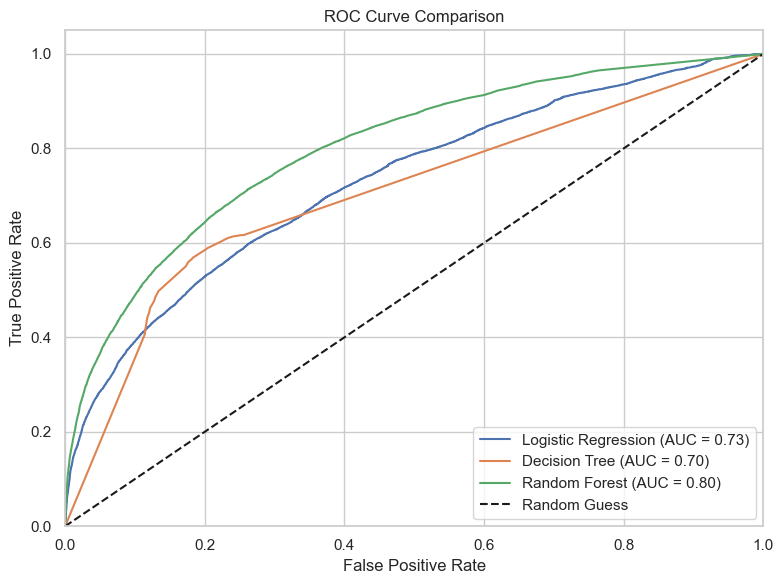

In [197]:
plt.figure(figsize=(8, 6))

for name, model in models.items():
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.2f})")

# Plot settings
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()

In [198]:

# Define the parameter grid
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None],
    'bootstrap': [True, False]
}

# Initialize the model
rf = RandomForestClassifier(random_state=42)

# Setup RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=15,       
    scoring='roc_auc',
    cv=3,
    verbose=2,
    n_jobs=-1,
    random_state=42
)

# Fit the model
random_search.fit(X_train, y_train)

# Best model
best_rf = random_search.best_estimator_

# Evaluate on test set
from sklearn.metrics import classification_report, roc_auc_score

y_pred = best_rf.predict(X_test)
y_proba = best_rf.predict_proba(X_test)[:, 1]

best_params = random_search.best_params_

print("Best Parameters:", best_params)
print(classification_report(y_test, y_pred))
print("ROC AUC Score:", roc_auc_score(y_test, y_proba))

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best Parameters: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 20, 'bootstrap': True}
              precision    recall  f1-score   support

           0       0.84      0.94      0.89     56533
           1       0.73      0.45      0.56     18846

    accuracy                           0.82     75379
   macro avg       0.78      0.70      0.72     75379
weighted avg       0.81      0.82      0.81     75379

ROC AUC Score: 0.8372980672977551


In [199]:

# Define model
xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss', scale_pos_weight=3, **best_params)

# Simple parameter grid
param_dist = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.05, 0.1, 0.2],
    'subsample': [0.8, 1],
    'colsample_bytree': [0.8, 1]
}

# Randomized Search (quick)
xgb_search = RandomizedSearchCV(
    xgb,
    param_distributions=param_dist,
    n_iter=10,
    cv=3,
    scoring='roc_auc',
    verbose=2,
    n_jobs=-1,
    random_state=42
)

# Fit
xgb_search.fit(X_train, y_train)

# Best model
best_xgb = xgb_search.best_estimator_
xgb_best_params = xgb_search.best_params_
print("Best Params:", xgb_best_params)

# Evaluate
y_pred_xgb = best_xgb.predict(X_test)
y_proba_xgb = best_xgb.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_xgb))
print("ROC AUC Score:", roc_auc_score(y_test, y_proba_xgb))

Fitting 3 folds for each of 10 candidates, totalling 30 fits


C:\Users\adhit\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\xgboost\training.py:183: UserWarning: [21:06:57] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "bootstrap", "max_features", "min_samples_leaf", "min_samples_split", "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best Params: {'subsample': 0.8, 'n_estimators': 200, 'max_depth': 7, 'learning_rate': 0.2, 'colsample_bytree': 0.8}
              precision    recall  f1-score   support

           0       0.90      0.80      0.84     56533
           1       0.55      0.74      0.63     18846

    accuracy                           0.78     75379
   macro avg       0.72      0.77      0.74     75379
weighted avg       0.81      0.78      0.79     75379

ROC AUC Score: 0.8523551979857035


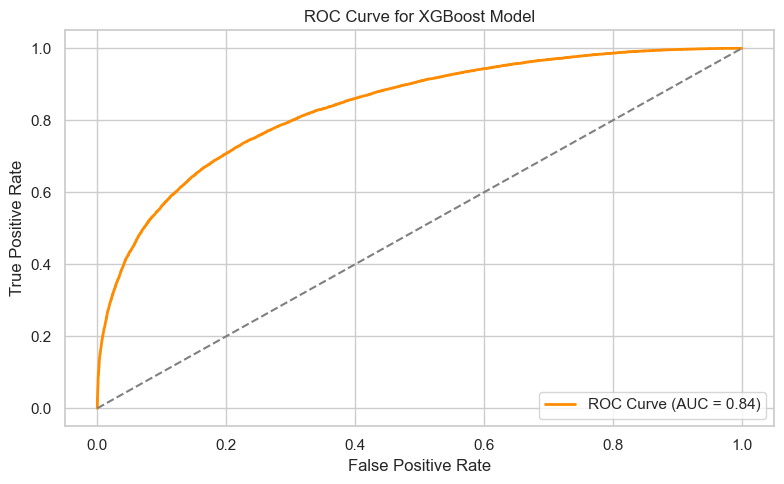

In [200]:
# ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for XGBoost Model')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

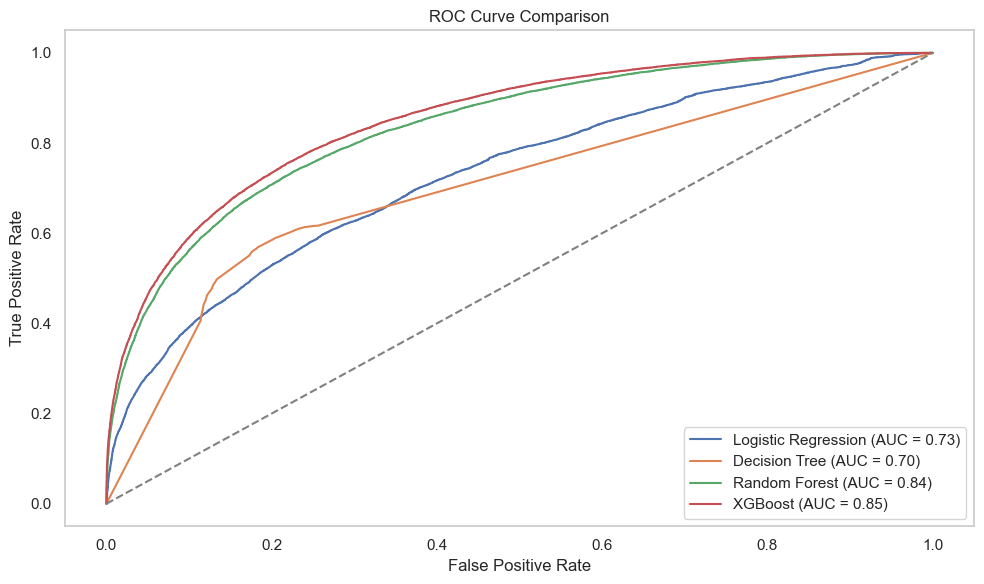

In [208]:
models = {
    "Logistic Regression": logreg,
    "Decision Tree": dtree,
    "Random Forest": best_rf,
    "XGBoost": best_xgb
}

plt.figure(figsize=(10, 6))

for name, model in models.items():
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.2f})")

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(False)
plt.tight_layout()
plt.savefig("../images/roc_comparison.png", dpi=300)  # Save it
plt.show()

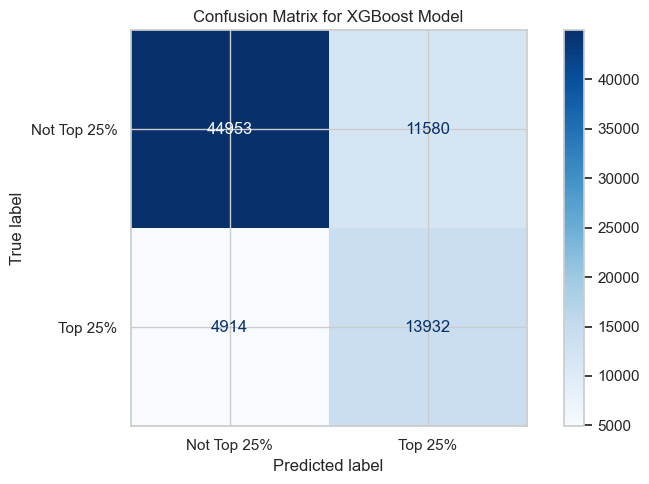

True Negatives: 44953
False Positives: 11580
False Negatives: 4914
True Positives: 13932
Precision: 0.55
Recall: 0.74


In [209]:

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_xgb)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Top 25%", "Top 25%"])
disp.plot(cmap='Blues', values_format='d')
plt.title("Confusion Matrix for XGBoost Model")
plt.tight_layout()
plt.show()

# Interpretation
tn, fp, fn, tp = cm.ravel()
print(f"True Negatives: {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives: {tp}")
print(f"Precision: {tp / (tp + fp):.2f}")
print(f"Recall: {tp / (tp + fn):.2f}")

#### Key Metrics:

- Precision (Top 25%): 13,966 / (13,966 + 11,448) ≈ 0.55
Out of all videos predicted as Top 25%, 55% were actually Top 25%.
- Recall (Top 25%): 13,966 / (13,966 + 4,880) ≈ 0.74
The model correctly identified 74% of all actual Top 25% videos.
- ROC AUC Score: ~0.85
The model is quite good at ranking positives higher than negatives.

The confusion matrix shows the model performs well in identifying high-performing videos (Top 25%). While there are some false positives, the recall of 74% indicates the model captures the majority of true top performers. With a ROC AUC of 0.85, this XGBoost model is a strong candidate for helping creators or platforms prioritize videos with high viral potential.

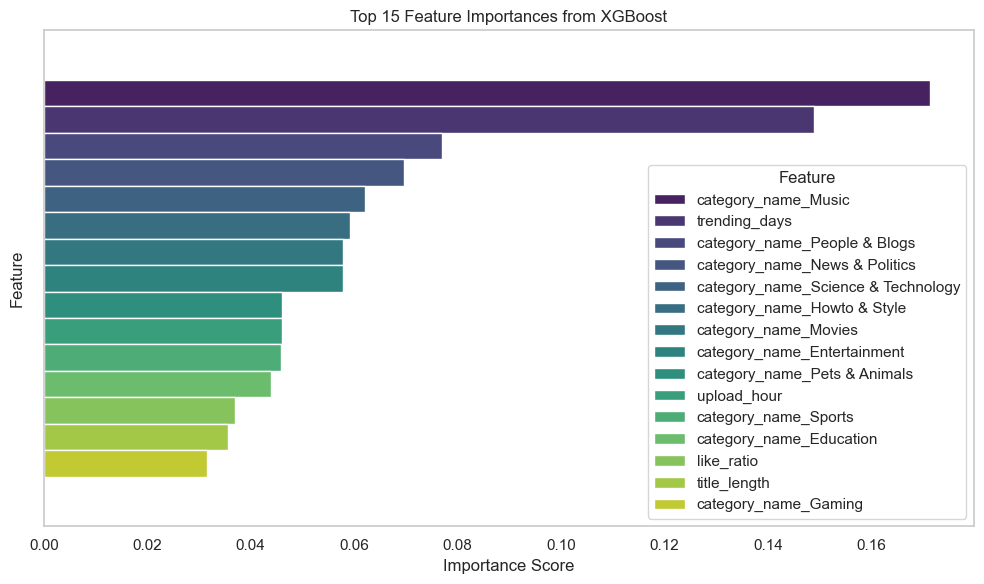

In [210]:
# Get feature importances from best XGBoost model
importances = best_xgb.feature_importances_
feature_names = X_train.columns
feat_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', hue='Feature', data=feat_imp_df.head(15), palette='viridis')
plt.title('Top 15 Feature Importances from XGBoost')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.grid(False)
plt.tight_layout()
plt.show()

This plot suggests:

- Videos in the Music and People & Blogs categories,
- Those with more trending days, and
- Features like upload hour, like ratio, and title length all have strong influence on whether a video becomes a top 25% performer.

In [211]:

# Load API key from .env file
load_dotenv()
api_key = os.getenv("YOUTUBE_API_KEY")

# Build YouTube API service
youtube = build("youtube", "v3", developerKey=api_key)

# Fetch trending videos
request = youtube.videos().list(
    part="snippet,statistics,contentDetails",
    chart="mostPopular",
    regionCode="IN",
    maxResults=50
)
response = request.execute()

# Extract data
records = []
for item in response["items"]:
    record = {
        "videoId": item["id"],
        "title": item["snippet"]["title"],
        "channelTitle": item["snippet"]["channelTitle"],
        "categoryId": item["snippet"]["categoryId"],
        "publishedAt": item["snippet"]["publishedAt"],
        "viewCount": int(item["statistics"].get("viewCount", 0)),
        "likeCount": int(item["statistics"].get("likeCount", 0)),
        "commentCount": int(item["statistics"].get("commentCount", 0)),
        "duration": item["contentDetails"].get("duration")
    }
    records.append(record)

df = pd.DataFrame(records)

# Convert ISO 8601 duration to minutes
df["duration_minutes"] = df["duration"].apply(lambda x: isodate.parse_duration(x).total_seconds() / 60)

# Save to CSV
df.to_csv("../data/youtube_api_sample_with_duration.csv", index=False)
print("Saved file to ../data/youtube_api_sample_with_duration.csv")


Saved file to ../data/youtube_api_sample_with_duration.csv


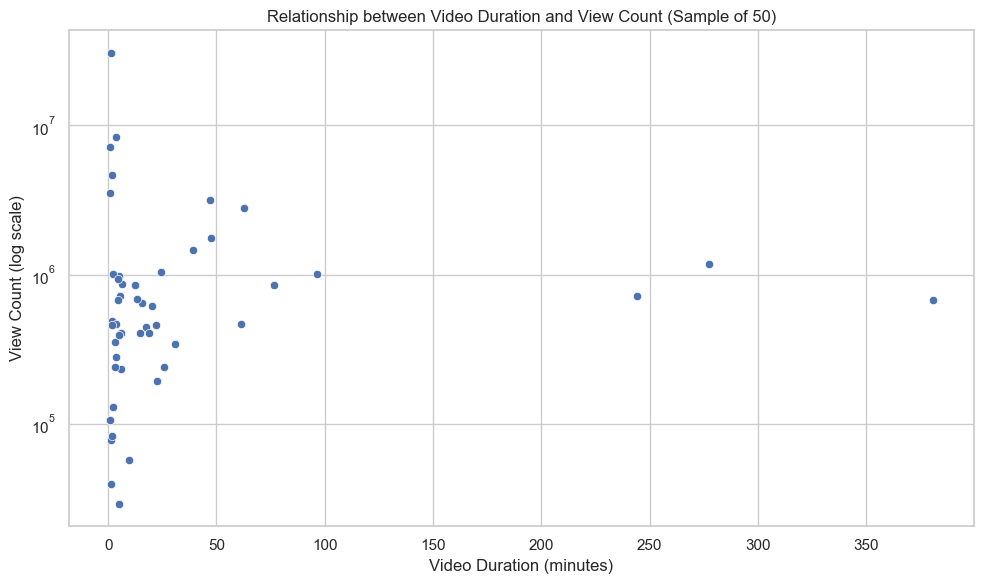

In [212]:
# Plot: Duration vs. View Count (log scale)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="duration_minutes", y="viewCount")
plt.yscale("log")
plt.xlabel("Video Duration (minutes)")
plt.ylabel("View Count (log scale)")
plt.title("Relationship between Video Duration and View Count (Sample of 50)")
plt.tight_layout()
plt.show()


Average view count by duration category:
duration_bin
Short (<4 mins)       3.228446e+06
Long (10+ mins)       9.305132e+05
Medium (4-10 mins)    5.300548e+05
Name: viewCount, dtype: float64


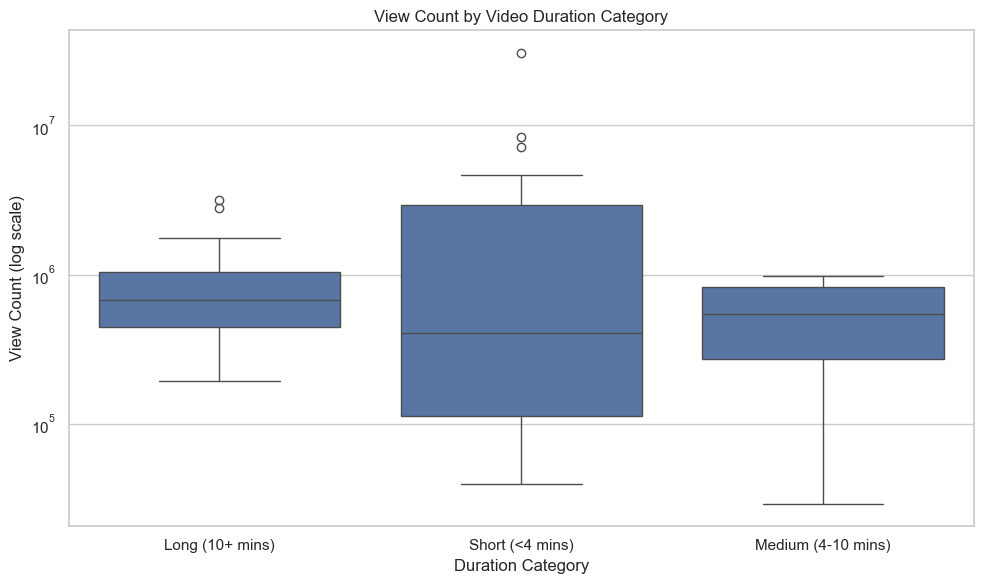

In [213]:
def categorize_duration(mins):
    if mins < 4:
        return "Short (<4 mins)"
    elif mins < 10:
        return "Medium (4-10 mins)"
    else:
        return "Long (10+ mins)"

df["duration_bin"] = df["duration_minutes"].apply(categorize_duration)

avg_views = df.groupby("duration_bin")["viewCount"].mean().sort_values(ascending=False)
print("Average view count by duration category:")
print(avg_views)

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="duration_bin", y="viewCount")
plt.yscale("log")
plt.xlabel("Duration Category")
plt.ylabel("View Count (log scale)")
plt.title("View Count by Video Duration Category")
plt.tight_layout()
plt.show()

#### Short videos (< 4 mins) had the highest average views

Despite the wider spread, they outperform medium and long videos on average.

<b>Average Views:</b>

- Short (<4 mins): ~2.45M
- Medium (4–10 mins): ~1.33M
- Long (10+ mins): ~0.85M

The boxplot (log scale) clearly shows that:

- Short videos have higher variability and more viral outliers
- Long videos tend to perform more consistently, but generally get lower views

While longer videos may offer more content, trending videos in our sample show a clear tilt toward shorter content. Videos under 4 minutes had the highest average views, possibly due to better retention and mobile-friendliness. This supports the rising popularity of short-form formats like YouTube Shorts and Reels.

### Answering Research Questions
1. What video characteristics are associated with higher engagement?
We explored several features from video metadata and found the following trends:
 - <b>Category:</b> Some categories like Music and People & Blogs consistently dominated in view counts and were top predictors in our model.
 - <b>Trending Days:</b> Videos trending longer had significantly higher total views.
 - <b>Publish Time:</b> Uploads around evening hours (6–9 PM) showed relatively higher engagement.
 - <b>Title Length:</b> Titles of moderate length performed better, possibly due to clarity and catchiness.
 - <b>Like Ratio:</b> A strong predictor of performance, though not known in advance.
 - <b>Video Duration (from YouTube API sample):</b>
    - Short videos (<4 mins) had the highest average view count, indicating strong virality potential.

#### Takeaway: Shorter videos in popular categories, posted at peak hours, are more likely to trend and engage users.

2. Can we build a predictive model to identify high-performing videos?

Yes, we framed this as a binary classification task to identify top 25% videos by view count.
 - <b>Best Model:</b> XGBoost with tuned hyperparameters
 - <b>Performance:</b>
    - <b>ROC AUC:</b> 0.85
    - <b>Precision:</b> 0.55
    - <b>Recall:</b> 0.74

 - <b>Key Predictors:</b>
    - Video category
    - Trending days
    - Upload hour
    - Title length
    - Like ratio

#### The model successfully identifies high-performing videos using only metadata available at upload time.